# Lab 7 — Principal Component Analysis (PCA)
## Seeds Dataset

**Donghyeon & Dae Young**

**Dataset Source:** https://archive.ics.uci.edu/dataset/236/seeds

In [ ]:
!pip -q install ucimlrepo

import numpy as np                          # For numerical operations
import pandas as pd                         # For loading and managing the dataset
import matplotlib.pyplot as plt             # For plotting the PCA scatter chart

from sklearn.preprocessing import StandardScaler   # For normalizing feature values
from sklearn.decomposition import PCA              # For reducing dimensions via PCA
from ucimlrepo import fetch_ucirepo                # For loading the UCI dataset

print('All libraries imported successfully!')

All libraries imported successfully!


In [ ]:
import pandas as pd

columns = [
    'Area', 'Perimeter', 'Compactness',
    'Kernel_length', 'Kernel_width',
    'Asymmetry', 'Groove_length', 'Seed_type'
]

seeds_dataset = pd.read_csv(
    'seeds_dataset.txt',
    sep=r'\s+',
    header=None,
    names=columns
)

print("Dataset shape:", seeds_dataset.shape)
print(seeds_dataset.head())

Dataset shape: (210, 8)
    Area  Perimeter  Compactness  Kernel_length  Kernel_width  Asymmetry  \
0  15.26      14.84       0.8710          5.763         3.312      2.221   
1  14.88      14.57       0.8811          5.554         3.333      1.018   
2  14.29      14.09       0.9050          5.291         3.337      2.699   
3  13.84      13.94       0.8955          5.324         3.379      2.259   
4  16.14      14.99       0.9034          5.658         3.562      1.355   

   Groove_length  Seed_type  
0          5.220          1  
1          4.956          1  
2          4.825          1  
3          4.805          1  
4          5.175          1  


In [ ]:
# Automatically identify features, excluding the label column
features = [col for col in seeds_dataset.columns if col != 'Seed_type']

print('Number of features:', len(features))  # Expected: 7
print('Feature names:', features)
print()
print('Label distribution (Seed_type):')
print(seeds_dataset['Seed_type'].value_counts().sort_index())
# Each wheat variety has 70 samples

Number of features: 7
Feature names: ['Area', 'Perimeter', 'Compactness', 'Kernel_length', 'Kernel_width', 'Asymmetry', 'Groove_length']

Label distribution (Seed_type):
Seed_type
1    70
2    70
3    70
Name: count, dtype: int64


In [ ]:
# Extract only the 7 feature columns (exclude Seed_type)
raw_features = seeds_dataset[features]

# Standardize all features
x = StandardScaler().fit_transform(raw_features)

print('Normalized data stats:')
print('  Mean : {:.6f}  (should be ~0)'.format(np.mean(x)))
print('  Std  : {:.6f}  (should be ~1)'.format(np.std(x)))
print('  Shape:', x.shape)  # Expected: (210, 7)

Normalized data stats:
  Mean : -0.000000  (should be ~0)
  Std  : 1.000000  (should be ~1)
  Shape: (210, 7)


In [ ]:
# Reduce 7 original dimensions to 2 principal components
pca = PCA(n_components=2)
principal_components = pca.fit_transform(x)

print('PCA output shape:', principal_components.shape)  # Expected: (210, 2)

pca_df = pd.DataFrame(principal_components, columns=['PC1', 'PC2'])
print()
print('First 5 rows of PCA result:')
print(pca_df.head())

PCA output shape: (210, 2)

First 5 rows of PCA result:
        PC1       PC2
0  0.317047 -0.783669
1 -0.003386 -1.913214
2 -0.459443 -1.907225
3 -0.591936 -1.931069
4  1.102910 -2.068090


In [ ]:
pc1_var, pc2_var = pca.explained_variance_ratio_

print('Explained variance per principal component:')
print('  PC1 : {:.1%}  — direction of greatest spread in the data'.format(pc1_var))
print('  PC2 : {:.1%}  — direction of second greatest spread'.format(pc2_var))
print('  ──────────────────────────────────────────────')
print('  Total: {:.1%}  of original variance retained in 2D'.format(pc1_var + pc2_var))

Explained variance per principal component:
  PC1 : 71.9%  — direction of greatest spread in the data
  PC2 : 17.1%  — direction of second greatest spread
  ──────────────────────────────────────────────
  Total: 89.0%  of original variance retained in 2D


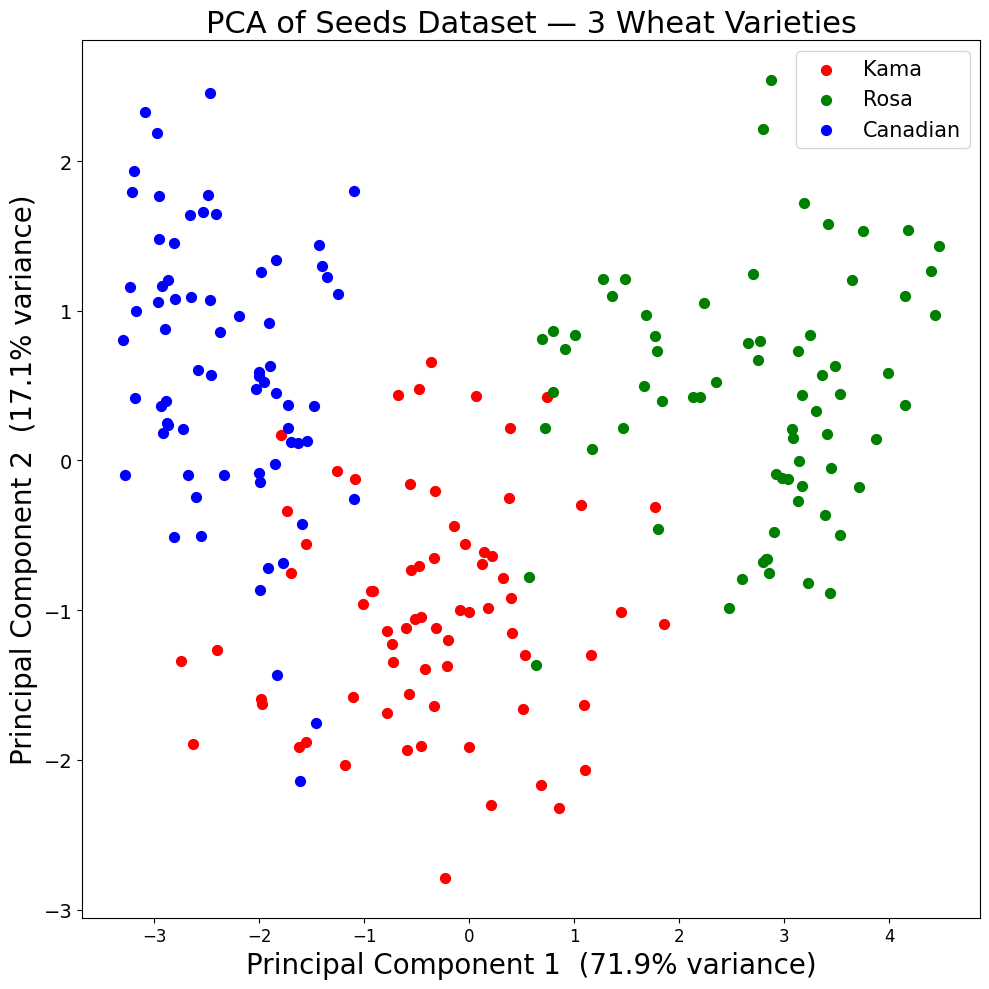

Plot saved as pca_seeds.png


In [ ]:
# Set up the figure canvas (same layout as the Wine example)
plt.figure(figsize=(10, 10))
plt.xlabel('Principal Component 1  ({:.1%} variance)'.format(pc1_var), fontsize=20)
plt.ylabel('Principal Component 2  ({:.1%} variance)'.format(pc2_var), fontsize=20)
plt.title('PCA of Seeds Dataset — 3 Wheat Varieties', fontsize=22)
plt.xticks(fontsize=12)
plt.yticks(fontsize=14)

colors = {
    1: ('r', 'Kama'),
    2: ('g', 'Rosa'),
    3: ('b', 'Canadian')
}

for label, (color, name) in colors.items():
    mask = seeds_dataset['Seed_type'] == label
    plt.scatter(
        pca_df.loc[mask, 'PC1'],
        pca_df.loc[mask, 'PC2'],
        c=color,
        s=50,
        label=name
    )

plt.legend(prop={'size': 15})
plt.tight_layout()
plt.savefig('pca_seeds.png', dpi=150)
plt.show()
print('Plot saved as pca_seeds.png')

### Explanation for a General Audience

This dataset contains 210 wheat seeds from three different varieties. Each seed has seven measurements, including area, perimeter, and length.

PCA reduced these seven features to two principal components (PC1 and PC2). PC1 explains approximately 71.9% of the variation, while PC2 explains 17.1%. Together, they preserve about 89.0% of the original variation.

The scatter plot shows how the three wheat varieties are distributed. Some groups are clearly separated, while others overlap.

This means PCA helps us visualize and understand the differences between wheat varieties using fewer variables.